In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv')

display(df.shape)
display(df.head())

(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

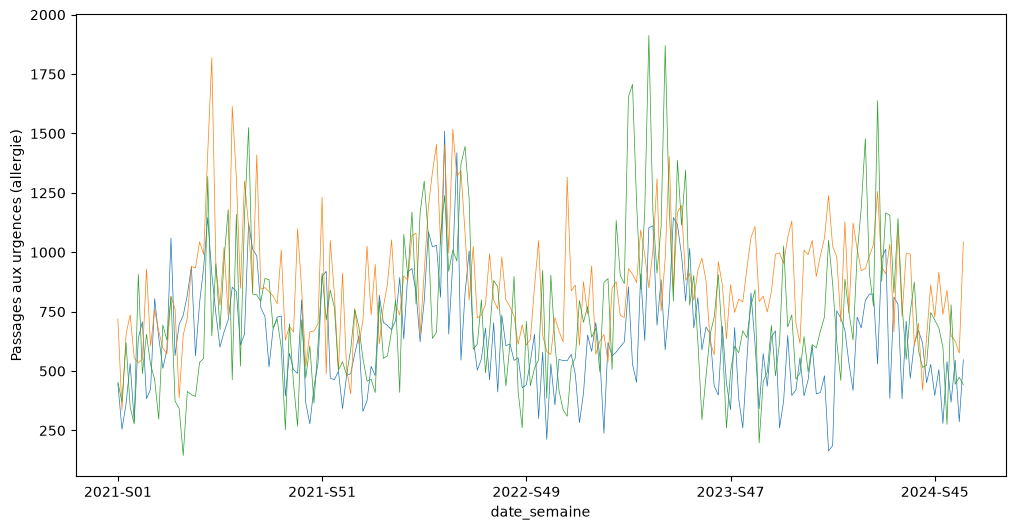

In [15]:
df.info()
print(df["TousAge_allergie_urgences"])
print(df["TousAge_allergie_urgences"].isna().sum())

piv = df.pivot_table(index='date_semaine', columns='code_dept',
                     values='TousAge_allergie_urgences')

piv[['01','02','03']].plot(figsize=(12, 6), legend=False, linewidth=0.5)
plt.ylabel('Passages aux urgences (allergie)')
plt.show()

26 cibles criblées


,n_dept,F_med,rho1_med,zeros_med,R2_persist_med,R2_profil_med,R2_baseline_med,pct_R2_neg,n_exclus
cible,,,,,,,,,
0an_bronchiolite_urgences,94,1.0,0.815,0.043,0.701,0.497,0.701,9.574,2
0an_bronchiolite_hospitalisation,75,1.0,0.712,0.125,0.436,0.158,0.444,9.333,21
0_14_asthme_urgences,96,1.0,0.591,0.005,0.125,0.127,0.217,33.333,0
TousAge_asthme_urgences,96,1.0,0.666,0.000,0.019,0.135,0.174,31.250,0
TousAge_allergie_urgences,96,1.0,0.429,0.000,-0.171,0.031,0.071,39.583,0
0_14_allergie+asthme_urgences,96,1.0,0.478,0.000,-0.030,-0.026,0.067,44.792,0
TousAge_allergie+asthme_urgences,96,1.0,0.512,0.000,-0.138,0.014,0.053,42.708,0
0_14_asthme_hospitalisation,92,1.0,0.385,0.139,-0.278,-0.032,-0.015,55.435,4
15_64_allergie_urgences,96,1.0,0.337,0.000,-0.225,-0.059,-0.016,54.167,0


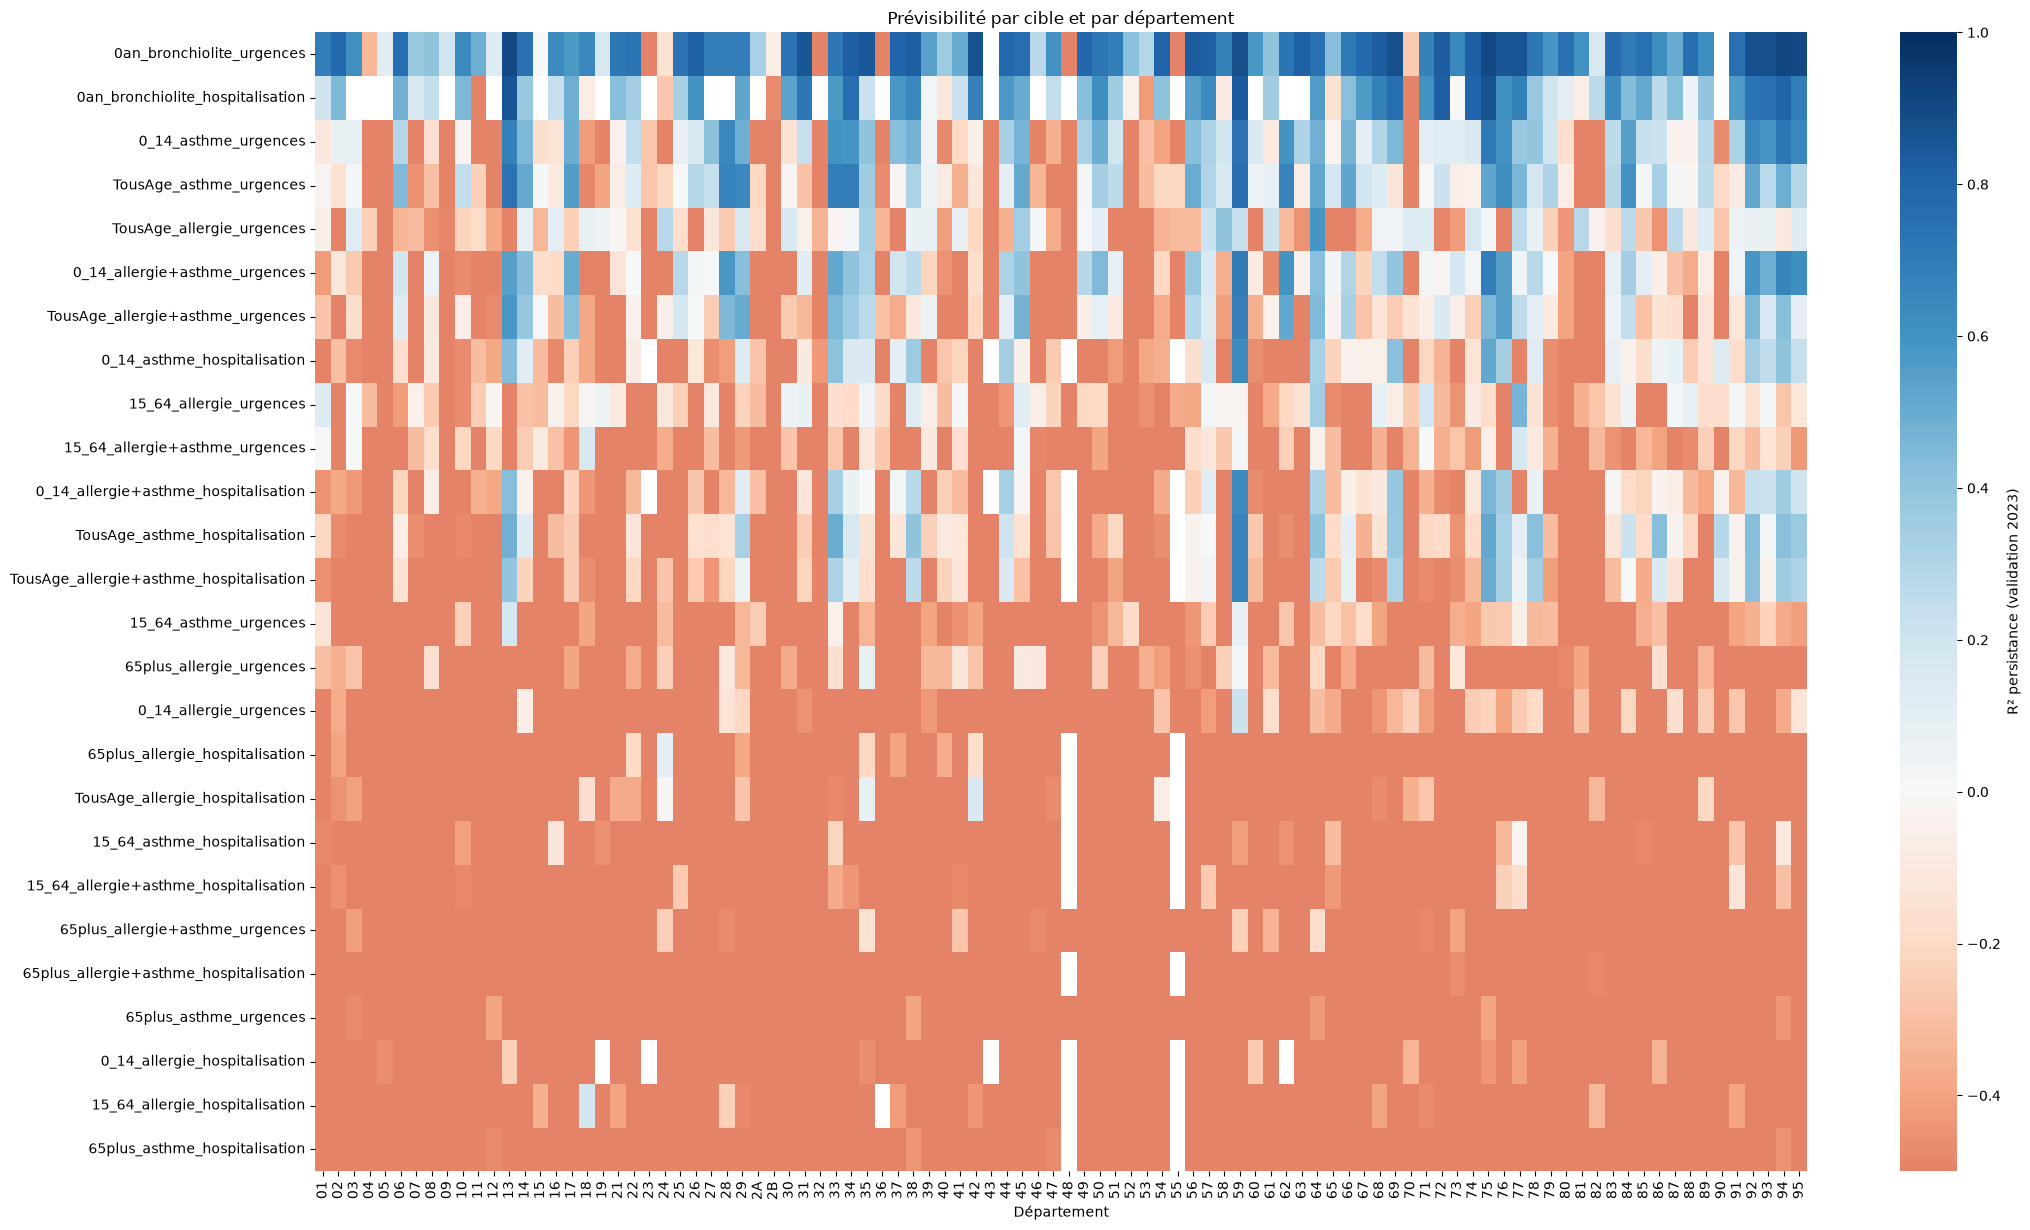

In [16]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")

SEUIL_MANQUANT = 0.10   # exclusion si > 10 % de semaines manquantes en train ou en val

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

motif = r"_(urgences|hospitalisation)$"

# --- Cibles regroupées : allergie + asthme, même classe d'âge ET même indicateur
#     (urgences avec urgences, hospitalisation avec hospitalisation ; dénominateur identique)
for c in [c for c in df.columns if re.search(motif, c) and "_allergie_" in c]:
    c_asthme = c.replace("_allergie_", "_asthme_")
    if c_asthme in df.columns:
        df[c.replace("_allergie_", "_allergie+asthme_")] = df[c] + df[c_asthme]   # NaN si l'une manque

cibles = [c for c in df.columns if re.search(motif, c)]
print(f"{len(cibles)} cibles criblées")

def force_saison(s):
    """Force de la saisonnalité (Hyndman) : 1 - Var(R) / Var(S + R).
    Les trous sont interpolés linéairement pour ce seul indicateur descriptif."""
    s = s.interpolate(limit_direction="both")
    res = seasonal_decompose(s, model="additive", period=52)
    r = res.resid.dropna()
    sa = res.seasonal.loc[r.index]
    return max(0, 1 - r.var() / (sa + r).var())

def r2_masque(y_true, y_pred):
    """R² sur les seules semaines où observation et prévision existent."""
    y_pred = pd.Series(np.asarray(y_pred, dtype=float), index=y_true.index)
    m = y_true.notna() & y_pred.notna()
    return r2_score(y_true[m], y_pred[m]) if m.sum() > 2 else np.nan

lignes = []
for c in cibles:
    tab = df.pivot(index="date", columns="code_dept", values=c).asfreq("W-MON")
    an = tab.index.year
    for dept in tab.columns:
        s = tab[dept]
        tr, va = s[an <= 2022], s[an == 2023]
        na_tr, na_va = tr.isna().mean(), va.isna().mean()
        # Exclusion : trop de valeurs manquantes, ou série constante
        if na_tr > SEUIL_MANQUANT or na_va > SEUIL_MANQUANT or tr.var() == 0 or va.var() == 0:
            lignes.append({"cible": c, "dept": dept, "exclu": True,
                           "na_train": na_tr, "na_val": na_va})
            continue
        # Baseline 1 : persistance (la semaine t vaut la semaine t-1 ; NaN après un trou)
        persist = s.shift(1)[an == 2023]
        # Baseline 2 : profil saisonnier = moyenne par semaine ISO sur 2021-2022 (NaN ignorés)
        profil_sem = tr.groupby(tr.index.isocalendar().week.astype(int)).mean()
        profil = profil_sem.reindex(va.index.isocalendar().week.astype(int)).values
        lignes.append({
            "cible": c, "dept": dept, "exclu": False,
            "na_train": na_tr, "na_val": na_va,
            "F": force_saison(tr),
            "rho1": tr.autocorr(1),                 # paires complètes uniquement
            "part_zeros": (tr == 0).mean(),
            "R2_persist": r2_masque(va, persist),
            "R2_profil": r2_masque(va, profil),
        })

crible = pd.DataFrame(lignes)
ok = crible[~crible["exclu"]].copy()
ok["R2_baseline"] = ok[["R2_persist", "R2_profil"]].max(axis=1)

# --- Synthèse par cible (médianes sur les départements)
synthese = ok.groupby("cible").agg(
    n_dept=("dept", "size"),
    F_med=("F", "median"),
    rho1_med=("rho1", "median"),
    zeros_med=("part_zeros", "median"),
    R2_persist_med=("R2_persist", "median"),
    R2_profil_med=("R2_profil", "median"),
    R2_baseline_med=("R2_baseline", "median"),
    pct_R2_neg=("R2_baseline", lambda x: 100 * (x < 0).mean()),
).sort_values("R2_baseline_med", ascending=False)
synthese["n_exclus"] = (crible[crible["exclu"]].groupby("cible").size()
                        .reindex(synthese.index, fill_value=0))
display(synthese.round(3))

# --- Heatmap cible × département : R² de la meilleure baseline sur 2023
mat = ok.pivot(index="cible", columns="dept", values="R2_persist").loc[synthese.index]
plt.figure(figsize=(22, 0.4 * len(mat) + 2))
sns.heatmap(mat, cmap="RdBu", center=0, vmin=-0.5, vmax=1,
            cbar_kws={"label": "R² persistance (validation 2023)"})
plt.title("Prévisibilité par cible et par département")
plt.xlabel("Département"); plt.ylabel("")
plt.tight_layout()
plt.show()

In [5]:
ok.query("cible == 'TousAge_asthme_urgences' and dept in ['59', '75', '13', '69', '33']")[
    ["dept", "rho1", "R2_persist", "R2_profil", "R2_baseline"]].round(3)

,dept,rho1,R2_persist,R2_profil,R2_baseline
588,13,0.876,0.741,0.566,0.741
609,33,0.819,0.695,0.575,0.695
635,59,0.836,0.759,0.787,0.787
645,69,0.784,-0.128,0.348,0.348
651,75,0.858,0.520,0.655,0.655


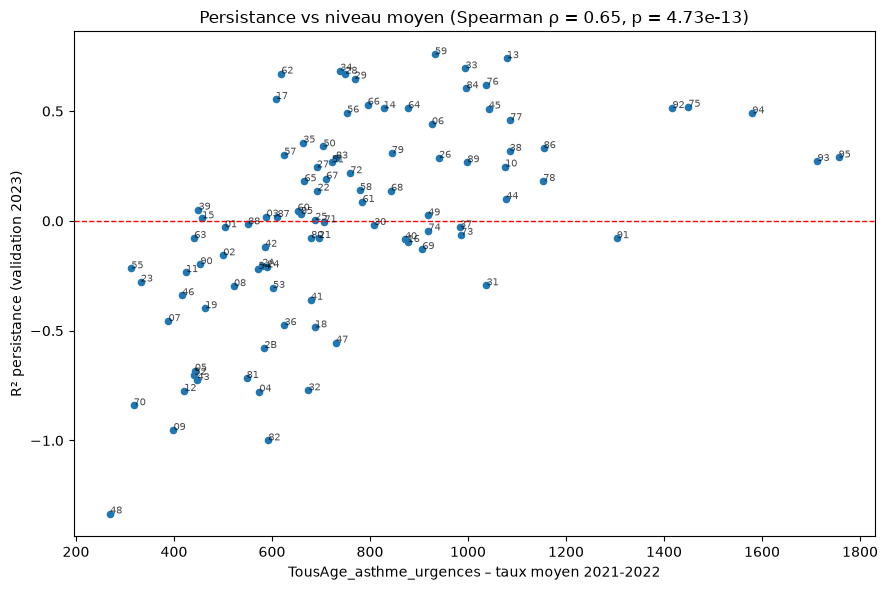

In [20]:
from scipy.stats import spearmanr

cible = "TousAge_asthme_urgences"

# X : niveau moyen de la cible par département sur 2021-2022 (train uniquement)
d = df[df["date"].dt.year <= 2022].groupby("code_dept")[cible].mean().rename("niveau_moyen")

# Y : R² de la persistance sur 2023, issu du criblage
r = ok.loc[ok["cible"] == cible].set_index("dept")["R2_persist"]

xy = pd.concat([d, r], axis=1, join="inner")
rho, p = spearmanr(xy["niveau_moyen"], xy["R2_persist"])

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(xy["niveau_moyen"], xy["R2_persist"], s=20)
for dept, row in xy.iterrows():                       # numéro de département sur chaque point
    ax.annotate(dept, (row["niveau_moyen"], row["R2_persist"]), fontsize=7, alpha=0.7)
ax.axhline(0, color="red", ls="--", lw=1)
ax.set_xlabel(f"{cible} – taux moyen 2021-2022")
ax.set_ylabel("R² persistance (validation 2023)")
ax.set_title(f"Persistance vs niveau moyen (Spearman ρ = {rho:.2f}, p = {p:.3g})")
plt.tight_layout()
plt.show()